#Tunneling to the Top!

Molly O'Donnell, Alexander Dorozynski, Siam Arafat Saad, Bibek Shrestha

## Importing all necessary libraries

In [ ]:
# Install necessary libraries
!pip install qiskit qiskit-machine-learning qiskit_algorithms pylatexenc

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

import pylatexenc

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel

from qiskit.circuit.library import zz_feature_map, RealAmplitudes
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.optimizers import SPSA
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.algorithms.classifiers import VQC

from sklearn.svm import SVC

##Upload and preprocess data

Split data into training, validation, and testing and scale as needed.

In [ ]:
# 1. Upload your CSV file from your computer
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please select your CSV file.")

# 2. Automatically get the exact uploaded filename
file_name = next(iter(uploaded.keys()))
print(f"Uploaded file: {file_name}")

# 3. Load the dataset
df = pd.read_csv(file_name)
print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print("Available columns:", df.columns.tolist())

# 4. Check required columns
features = ['INCLINATION', 'ECCENTRICITY', 'MEAN_MOTION', 'BSTAR']
target = 'label'

required_columns = features + [target]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# 5. Separate features (X) and target (y)
X = df[features].values
y = df[target].values

# 6. Split: 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# 7. Scale features between 0 and pi for quantum circuits
scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 8. Display dataset shapes
print("\nPreprocessing completed successfully!")
print(f"Training data shape:   {X_train_scaled.shape}")
print(f"Validation data shape: {X_val_scaled.shape}")
print(f"Test data shape:       {X_test_scaled.shape}")

Saving Interstate QHack 2026.csv.csv to Interstate QHack 2026.csv (1).csv
Uploaded file: Interstate QHack 2026.csv (1).csv
Dataset loaded successfully!
Dataset shape: (300, 6)
Available columns: ['INCLINATION', 'ECCENTRICITY', 'MEAN_MOTION', 'BSTAR', 'OBJECT_TYPE', 'label']

Preprocessing completed successfully!
Training data shape:   (180, 4)
Validation data shape: (60, 4)
Test data shape:       (60, 4)


##Train and assess quantum ML algorithm (provided in hackathon notebooks)

In [ ]:
# 1. Create ZZ Feature Map for 4 qubits (because we have 4 features)
# reps=2 means we repeat the circuit twice for better learning
feature_map = zz_feature_map(feature_dimension=4, reps=2)

# 2. Initialize the Quantum Kernel
q_kernel = FidelityStatevectorKernel(feature_map=feature_map)

# 3. Initialize Quantum Support Vector Classifier (QSVC)
qsvc = QSVC(quantum_kernel=q_kernel)

print("Training the Quantum Model... Please wait, this might take a few minutes.")
start_time = time.time()

# 4. Train the model using the training data
qsvc.fit(X_train_scaled, y_train)

# 5. Check the accuracy on Training and Test data
qsvc_train_acc = qsvc.score(X_train_scaled, y_train)
qsvc_val_acc = qsvc.score(X_val_scaled, y_val)

print(f"Training finished in {time.time() - start_time:.2f} seconds!")
print(f"Training Accuracy: {qsvc_train_acc * 100:.2f}%")
print(f"Validation Accuracy: {qsvc_val_acc * 100:.2f}%")

Training the Quantum Model... Please wait, this might take a few minutes.
Training finished in 2.46 seconds!
Training Accuracy: 97.78%
Test Accuracy: 88.33%


## Train and assess classical machine learning algorithm

In [ ]:
# 1. Train a Classical SVM model on the same dataset
classical_svm = SVC(kernel='rbf', random_state=42)
classical_svm.fit(X_train_scaled, y_train)

# 2. Calculate Classical Accuracies
classical_train_acc = classical_svm.score(X_train_scaled, y_train)
classical_val_acc = classical_svm.score(X_val_scaled, y_val)

print("--- Model Comparison ---")
print(f"Classical SVM Validation Accuracy: {classical_val_acc * 100:.2f}%")
print(f"Quantum SVM Validation Accuracy:   {qsvc_val_acc * 100:.2f}%")

--- Model Comparison ---
Classical SVM Validation Accuracy: 83.33%
Quantum SVM Validation Accuracy:   88.33%


## Train and assess Variational Quantum Classifier

Using a Simultaneous Perturbation Stochastic Approximation (SPSA) optimizer

Source: https://medium.com/@zaw.myinttun/quantum-machine-learning-basics-building-a-variational-quantum-classifier-with-qiskit-a9e01b2d45ea

In [ ]:
# 1. Encode features into quantum states
VQC_feature_map = zz_feature_map(feature_dimension=4, reps=2, entanglement = "linear")

# 2. Create the variationa circuit
ansatz = RealAmplitudes(num_qubits = 4, reps = 2)

# 3. Display circuit diagrams
print("Feature Map (ZZFeatureMap)")
display(feature_map.decompose().draw())

print("Ansatz (RealAmplitudes)")
display(ansatz.decompose().draw())

Feature Map (ZZFeatureMap)


/tmp/ipykernel_2103/930779428.py:3: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits = 4, reps = 2)  # Variational circuit


┌────────────┐┌───────────────┐                                         »
0: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[0]) ├──■──────────────────────────────────────»
   ├────────────┤├───────────────┤┌─┴─┐┌──────────────────────────────────┐»
1: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[1]) ├┤ X ├┤ U(0,0,(-π + x[0])*(-π + x[1])*2) ├»
   ├────────────┤├───────────────┤└───┘└──────────────────────────────────┘»
2: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[2]) ├─────────────────────────────────────────»
   ├────────────┤├───────────────┤                                         »
3: ┤ U(π/2,0,π) ├┤ U(0,0,2*x[3]) ├─────────────────────────────────────────»
   └────────────┘└───────────────┘                                         »
«                                                                »
«0: ──■────■────────────────────────────────────────■─────────■──»
«   ┌─┴─┐  │                                        │         │  »
«1: ┤ X ├──┼────────────────────────────────────────┼────■────┼──»
«   └───┘┌─┴─┐┌──────────────────────────────────┐┌─┴─┐┌─┴─┐  │  »
«2: ─────┤ X ├┤ U(0,0,(-π + x[0])*(-π + x[2])*2) ├┤ X ├┤ X ├──┼──»
«        └───┘└──────────────────────────────────┘└───┘└───┘┌─┴─┐»
«3: ────────────────────────────────────────────────────────┤ X ├»
«                                                           └───┘»
«                                                 ┌────────────┐»
«0: ───────────────────────────────────────────■──┤ U(π/2,0,π) ├»
«                                              │  └────────────┘»
«1: ──────────────────────────────────────■────┼────────■───────»
«   ┌──────────────────────────────────┐┌─┴─┐  │        │       »
«2: ┤ U(0,0,(-π + x[1])*(-π + x[2])*2) ├┤ X ├──┼────────┼───────»
«   ├──────────────────────────────────┤└───┘┌─┴─┐    ┌─┴─┐     »
«3: ┤ U(0,0,(-π + x[0])*(-π + x[3])*2) ├─────┤ X ├────┤ X ├─────»
«   └──────────────────────────────────┘     └───┘    └───┘     »
«            ┌───────────────┐                             »
«0: ─────────┤ U(0,0,2*x[0]) ├─────────────────────────────»
«            └───────────────┘               ┌────────────┐»
«1: ──────────────────────────────────────■──┤ U(π/2,0,π) ├»
«                                         │  └────────────┘»
«2: ──────────────────────────────────────┼────────■───────»
«   ┌──────────────────────────────────┐┌─┴─┐    ┌─┴─┐     »
«3: ┤ U(0,0,(-π + x[1])*(-π + x[3])*2) ├┤ X ├────┤ X ├─────»
«   └──────────────────────────────────┘└───┘    └───┘     »
«                                            »
«0: ──────────────────────────────────────■──»
«            ┌───────────────┐          ┌─┴─┐»
«1: ─────────┤ U(0,0,2*x[1]) ├──────────┤ X ├»
«            └───────────────┘          └───┘»
«2: ──────────────────────────────────────■──»
«   ┌──────────────────────────────────┐┌─┴─┐»
«3: ┤ U(0,0,(-π + x[2])*(-π + x[3])*2) ├┤ X ├»
«   └──────────────────────────────────┘└───┘»
«                                                             »
«0: ────────────────────────────────────────────■──────────■──»
«   ┌──────────────────────────────────┐      ┌─┴─┐        │  »
«1: ┤ U(0,0,(-π + x[0])*(-π + x[1])*2) ├──────┤ X ├────────┼──»
«   └──────────┬────────────┬──────────┘┌─────┴───┴─────┐┌─┴─┐»
«2: ───────────┤ U(π/2,0,π) ├───────────┤ U(0,0,2*x[2]) ├┤ X ├»
«              ├────────────┤           ├───────────────┤└───┘»
«3: ───────────┤ U(π/2,0,π) ├───────────┤ U(0,0,2*x[3]) ├─────»
«              └────────────┘           └───────────────┘     »
«                                                      »
«0: ──────────────────────────────────────■─────────■──»
«                                         │         │  »
«1: ──────────────────────────────────────┼────■────┼──»
«   ┌──────────────────────────────────┐┌─┴─┐┌─┴─┐  │  »
«2: ┤ U(0,0,(-π + x[0])*(-π + x[2])*2) ├┤ X ├┤ X ├──┼──»
«   └──────────────────────────────────┘└───┘└───┘┌─┴─┐»
«3: ──────────────────────────────────────────────┤ X ├»
«                                                 └───┘»
«                                                   

Ansatz (RealAmplitudes)


┌──────────┐                             ┌──────────┐             »
q_0: ┤ Ry(θ[0]) ├──────────────────────■──────┤ Ry(θ[4]) ├─────────────»
     ├──────────┤                    ┌─┴─┐    ├──────────┤             »
q_1: ┤ Ry(θ[1]) ├──────────■─────────┤ X ├────┤ Ry(θ[5]) ├──────■──────»
     ├──────────┤        ┌─┴─┐    ┌──┴───┴───┐└──────────┘    ┌─┴─┐    »
q_2: ┤ Ry(θ[2]) ├──■─────┤ X ├────┤ Ry(θ[6]) ├─────■──────────┤ X ├────»
     ├──────────┤┌─┴─┐┌──┴───┴───┐└──────────┘   ┌─┴─┐    ┌───┴───┴───┐»
q_3: ┤ Ry(θ[3]) ├┤ X ├┤ Ry(θ[7]) ├───────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└───┘└──────────┘               └───┘    └───────────┘»
«                  ┌──────────┐
«q_0: ──────■──────┤ Ry(θ[8]) ├
«         ┌─┴─┐    ├──────────┤
«q_1: ────┤ X ├────┤ Ry(θ[9]) ├
«     ┌───┴───┴───┐└──────────┘
«q_2: ┤ Ry(θ[10]) ├────────────
«     └───────────┘            
«q_3: ─────────────────────────
«

In [ ]:
# 1. Track loss values during training
objective_func_vals = []

# 2. Define callback to log training loss
def callback_graph(*args):
    if len(args) >= 5:
        obj_func_eval = args[2]   # loss value is the 3rd argument
        objective_func_vals.append(obj_func_eval)
        if len(objective_func_vals) % 5 == 0:
            print(f"Evaluation {len(objective_func_vals)} → Loss = {obj_func_eval:.4f}")

# 3. Configure SPSA optimizer
optimizer = SPSA(maxiter=150, learning_rate=0.1, perturbation=0.1)

# 4. Initialize VQC with feature map, ansatz, and optimizer
vqc = VQC(
    sampler=StatevectorSampler(),
    feature_map=VQC_feature_map,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback_graph,
    loss='cross_entropy'
)

# 5. Train VQC and report runtime
print("Starting VQC training with SPSA optimizer...")
start = time.time()
# LINE BELOW FITS THE MODEL - TAKES ABOUT 8 MINS ON LAPTOP
vqc.fit(X_train_scaled, y_train)
print(f"Training finished in {time.time() - start:.1f} seconds")

Starting VQC training with SPSA optimizer...
Evaluation 5 → Loss = 1.1026
Evaluation 10 → Loss = 0.9985
Evaluation 15 → Loss = 0.9294
Evaluation 20 → Loss = 0.9084
Evaluation 25 → Loss = 0.8899
Evaluation 30 → Loss = 0.8793
Evaluation 35 → Loss = 0.8734
Evaluation 40 → Loss = 0.8670
Evaluation 45 → Loss = 0.8728
Evaluation 50 → Loss = 0.8603
Evaluation 55 → Loss = 0.8577
Evaluation 60 → Loss = 0.8478
Evaluation 65 → Loss = 0.8522
Evaluation 70 → Loss = 0.8442
Evaluation 75 → Loss = 0.8354
Evaluation 80 → Loss = 0.8353
Evaluation 85 → Loss = 0.8272
Evaluation 90 → Loss = 0.8288
Evaluation 95 → Loss = 0.8234
Evaluation 100 → Loss = 0.8272
Evaluation 105 → Loss = 0.8266
Evaluation 110 → Loss = 0.8176
Evaluation 115 → Loss = 0.8192
Evaluation 120 → Loss = 0.8191
Evaluation 125 → Loss = 0.8147
Evaluation 130 → Loss = 0.8085
Evaluation 135 → Loss = 0.8065
Evaluation 140 → Loss = 0.8075
Evaluation 145 → Loss = 0.8028
Evaluation 150 → Loss = 0.8003
Training finished in 726.8 seconds


In [ ]:
# 1. Calculate score for VQC model
vqc_train_acc = vqc.score(X_train_scaled, y_train)
vqc_val_acc  = vqc.score(X_val_scaled, y_val)

# 2. Display score
print(f"Training accuracy: {vqc_train_acc:.4f}")
print(f"Validation accuracy: {vqc_val_acc:.4f}")

Training accuracy: 0.7056
Validation accuracy: 0.7333


##Final test of the quantum algorithm

(Should only be done once we've decided officially on a final model, so I'll keep it commented out in case the second quantum model seems to perform better than the one we were given by the hackathon notebooks)

In [ ]:
# 1. Evaluate trained QSVC on held-out test data
test_acc = qsvc.score(X_test_scaled, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Accuracy: 86.67%


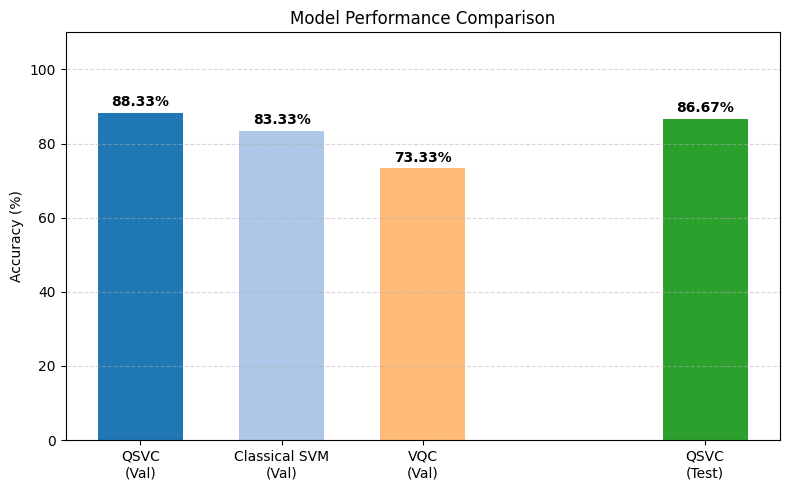

In [ ]:
# 1. Set up positions for the bars
# Placing validation models close together, and test score farther to the right
positions = [1, 2, 3, 5]

accuracies = [
    qsvc_val_acc * 100,
    classical_val_acc * 100,
    vqc_val_acc * 100,
    test_acc * 100
]

labels = [
    'QSVC\n(Val)',
    'Classical SVM\n(Val)',
    'VQC\n(Val)',
    'QSVC\n(Test)'
]

colors = ['#1f77b4', '#aec7e8', '#ffbb78', '#2ca02c']

# 2. Create the plot
plt.figure(figsize=(8, 5))
bars = plt.bar(positions, accuracies, color=colors, width=0.6)

# 3. Add values on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 1, f'{height:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.xticks(positions, labels)
plt.ylabel('Accuracy (%)')
plt.title('Model Performance Comparison')
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Classical K-Means


In [52]:
def majority_score(labels):
    # Each cluster counts as whichever type (debris or payload) is most common in it
    return sum(max((y[labels == c] == 0).sum(), (y[labels == c] == 1).sum())
               for c in np.unique(labels)) / len(y)

In [ ]:
# 1. Scale all features to 0-1 range
X_all_scaled = MinMaxScaler().fit_transform(df[features].values)

# 2. Fit K-Means with two clusters
km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_all_scaled)
print(pd.crosstab(df['OBJECT_TYPE'], km.labels_))

# 3. Fit K-Means with three clusters
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_all_scaled)
print()
print(pd.crosstab(df['OBJECT_TYPE'], km.labels_))

# 4. Inspect objects assigned to cluster 0
print()
print(df[km.labels_ == 0])

col_0         0    1
OBJECT_TYPE         
DEBRIS        4  146
PAYLOAD      11  139

col_0          0   1   2
OBJECT_TYPE             
DEBRIS       118  28   4
PAYLOAD       47  92  11

     INCLINATION  ECCENTRICITY  MEAN_MOTION     BSTAR OBJECT_TYPE  label  \
0        98.9085      0.007707    14.037226  0.000151      DEBRIS      1   
1        98.6825      0.002308    14.263888  0.001126      DEBRIS      1   
2        82.9624      0.003944    13.755272  0.000066      DEBRIS      1   
4        98.6835      0.011564    13.908836  0.000082      DEBRIS      1   
5        98.5789      0.009284    14.246302  0.000199      DEBRIS      1   
..           ...           ...          ...       ...         ...    ...   
290      97.2857      0.000288    15.334083  0.000605     PAYLOAD      0   
291      99.5445      0.004562    14.469699  0.000613      DEBRIS      1   
292      87.9153      0.000186    13.176515 -0.000075     PAYLOAD      0   
293      98.6225      0.004096    14.235376  0.000680 

Ploting inclination against mean motion


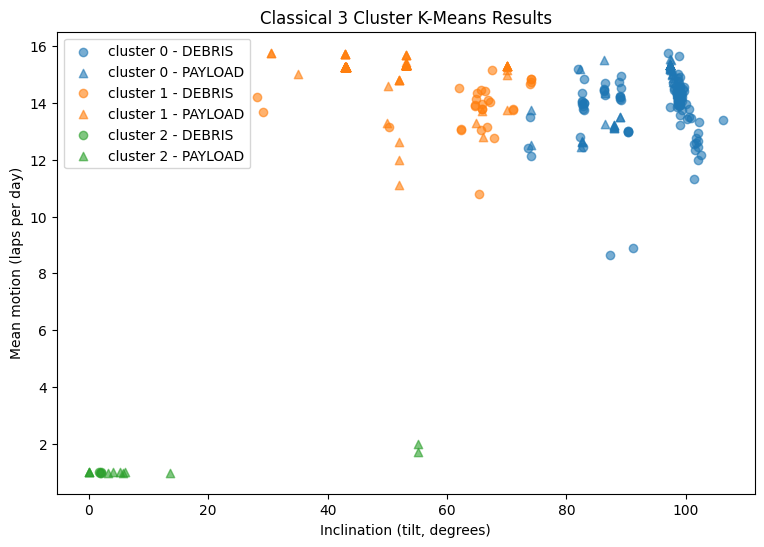

In [ ]:
# 1. Refit K-Means and store cluster labels
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_all_scaled)
df['cluster'] = km3.labels_

# 2. Define cluster colors and object-type markers
colors = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}
shapes = {'DEBRIS': 'o', 'PAYLOAD': '^'}

# 3. Scatter plot of inclination against mean motion
plt.figure(figsize=(9, 6))
for c in range(3):
    for t, m in shapes.items():
        sub = df[(df.cluster == c) & (df.OBJECT_TYPE == t)]
        plt.scatter(sub.INCLINATION, sub.MEAN_MOTION, color=colors[c],
                    marker=m, alpha=0.6, label=f'cluster {c} - {t}')
plt.title("Classical 3 Cluster K-Means Results")
plt.xlabel('Inclination (tilt, degrees)')
plt.ylabel('Mean motion (laps per day)')
plt.legend()
plt.show()

## Quantum-Kernel K-Means Clustering

In [ ]:
# 1. Quantum scaling (0 to pi), same as the QSVC cell
X_q = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(df[features].values)

# 2. Quantum similarity table: 300 x 300
K_q = q_kernel.evaluate(X_q)

# 3. Cluster using precomputed quantum kernel
sc_q = SpectralClustering(n_clusters=2, affinity='precomputed',
                          random_state=42).fit(K_q)

# 4. Compare quantum clusters with object types
print(pd.crosstab(df['OBJECT_TYPE'], sc_q.labels_))

col_0         0    1
OBJECT_TYPE         
DEBRIS       29  121
PAYLOAD      94   56


Agreement number and running the classical comparison

In [55]:
# 1. Extract true labels
y = df['label'].values

# 2. Define agreement score between cluster labels and true labels
def agreement(labels):
    return max((labels == y).mean(), (labels != y).mean())

# 3. Report quantum kernel agreement
print('Quantum kernel:  ', agreement(sc_q.labels_))

# 4. Build classical RBF kernel and cluster
K_c = rbf_kernel(X_q)
sc_c = SpectralClustering(n_clusters=2, affinity='precomputed',
                          random_state=42).fit(K_c)
sc_c3 = SpectralClustering(n_clusters=3, affinity='precomputed',
                          random_state=42).fit(K_c)

# 5. Report classical kernel agreement
print('Classical kernel (2 groups):', agreement(sc_c.labels_))

print("Classical kernel (3 groups): ", majority_score(sc_c3.labels_))

Quantum kernel:   0.7166666666666667
Classical kernel (2 groups): 0.5166666666666667
Classical kernel (3 groups):  0.7433333333333333


Checking the gamma kernal fairness

In [ ]:
# 1. Sweep RBF gamma values for kernel fairness check
for g in [0.05, 0.1, 0.25, 0.5, 1, 2, 5]:
    K = rbf_kernel(X_q, gamma=g)
    # Cluster and score agreement for each gamma
    sc = SpectralClustering(n_clusters=2, affinity='precomputed',
                            random_state=42).fit(K)
    print(g, round(agreement(sc.labels_), 3))

0.05 0.523
0.1 0.517
0.25 0.517
0.5 0.517
1 0.523
2 0.523
5 0.523


# Part 2: Fair comparison on filtered data, noise and IBM hardware
*(Bibek)*

Part 1 showed promising results on our 300-object sample: QSVC 88.3% vs classical SVM 83.3%, and Storm's k-means found the data splits by orbit altitude. Part 2 builds on these findings:

1. **Filtered data:** following Storm's k-means finding, we keep only low Earth orbit (LEO) and remove megaconstellations (Starlink, OneWeb, ...), so models cannot simply detect altitude. We still use 300 objects (150 debris + 150 payloads) per run.
2. **Fair comparison:** quantum and classical models are both tuned, and every experiment is repeated on 10 random samples (seeds), reporting mean ± std.
3. **Bandwidth λ:** how the data is scaled before entering the quantum circuit turns out to decide whether the quantum kernel works.
4. **Noise:** the same kernel under shot noise and simulated IBM device noise.
5. **Real IBM hardware:** the kernel measured on ibm_kingston.

In [ ]:
!pip install -q qiskit qiskit-machine-learning qiskit-aer qiskit-ibm-runtime pandas scikit-learn matplotlib

# Core libraries (also imported in Part 1; repeated so Part 2 can run on its own)
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

# Upload full dataset
from google.colab import drive
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please select your CSV file.")

# Automatically get the exact uploaded filename
file_name = next(iter(uploaded.keys()))
print(f"Uploaded file: {file_name}")

# Settings for Part 2
FEATURES = ["INCLINATION", "ECCENTRICITY", "MEAN_MOTION", "BSTAR"]   # same 4 features as Part 1
N_QUBITS = len(FEATURES)    # one feature = one qubit
SEEDS = range(10)           # repeat each experiment on 10 random samples, report mean ± std

Saving SpaceDebris_PartTwo.csv.csv to SpaceDebris_PartTwo.csv.csv
Uploaded file: SpaceDebris_PartTwo.csv.csv


## 2.1 Filtered data and fair splits

**Source:** full Space-Track.org catalog (32,383 tracked objects), the same source as Part 1's 300-object sample.

**Why we filter (building on Storm's k-means result):**
- **LEO only** (perigee below 2,000 km): high orbits such as GEO (mean motion about 1 lap/day) are almost all payloads, so a model can "cheat" by detecting altitude. This is what k-means picked up in Part 1.
- **Remove megaconstellations** (Starlink, OneWeb, Qianfan, Kuiper, Guowang): over 11,000 Starlink satellites alone sit at nearly identical orbits, making a random payload sample artificially easy.

**After filtering:** 9,774 debris and 4,623 payloads, plus 1,199 objects labeled UNKNOWN.

**`make_split(seed)`:** draws 150 debris + 150 payloads (300, same size as Part 1), splits 60/20/20 into train/validation/test, and rescales features with a quantile transform fitted on training data only (handles BSTAR's extreme outliers better than min-max). Each seed gives a different random sample.

In [ ]:
# 2.1 Load the full catalog, filter it, define a fair split

raw = pd.read_csv(file_name, low_memory=False)

# Filter 1: Low Earth Orbit only.  Filter 2: remove megaconstellations.
MEGA = "STARLINK|ONEWEB|QIANFAN|KUIPER|GUOWANG"
leo = raw[(raw["PERIAPSIS"] < 2000) & ~raw["OBJECT_NAME"].str.contains(MEGA, na=False)]

# Labeled pool: debris (1) vs payload (0)
labeled = leo[leo["OBJECT_TYPE"].isin(["DEBRIS", "PAYLOAD"])].copy()
labeled["label"] = (labeled["OBJECT_TYPE"] == "DEBRIS").astype(int)

# Objects with no label (not used in Part 2's core results)
unknown = leo[leo["OBJECT_TYPE"] == "UNKNOWN"].copy()

# Expected: (32383, 40), (14397, 41), (1199, 40); 9774 debris, 4623 payload
print("full catalog:", raw.shape, " labeled LEO pool:", labeled.shape, " unknown LEO:", unknown.shape)
print(labeled["OBJECT_TYPE"].value_counts())


def make_split(seed, n_per_class=150):
    """Balanced 150/150 sample, split 60/20/20 (train/validation/test),
    quantile-scaled to [0, 1] using the training data only (no leakage)."""
    s = pd.concat([labeled[labeled.label == k].sample(n_per_class, random_state=seed) for k in (0, 1)])
    X, y = s[FEATURES].values, s["label"].values
    Xtr, Xtmp, ytr, ytmp = train_test_split(X, y, test_size=0.4, random_state=seed, stratify=y)
    Xva, Xte, yva, yte = train_test_split(Xtmp, ytmp, test_size=0.5, random_state=seed, stratify=ytmp)
    qt = QuantileTransformer(n_quantiles=min(100, len(Xtr)), output_distribution="uniform").fit(Xtr)
    return qt.transform(Xtr), ytr, qt.transform(Xva), yva, qt.transform(Xte), yte, qt

full catalog: (32383, 40)  labeled LEO pool: (14397, 41)  unknown LEO: (1199, 40)
OBJECT_TYPE
DEBRIS     9774
PAYLOAD    4623
Name: count, dtype: int64


Fair comparison of quantum and classical models
In Part 1 we compared the QSVC to a classical SVM with default settings on one split. Here we give every model a fair chance by tuning its settings on the validation set, and we repeat the whole experiment on 10 different random samples. We report the average accuracy and how much it varies (± std).

For the quantum model we tune two settings: C (how strictly the SVM fits the training data) and the bandwidth λ, which controls how spread out the data is when it goes into the quantum circuit (features are scaled to [0, λπ]).

Finished in 144 seconds

                      mean    std
model                            
Random forest        0.888  0.047
Logistic regression  0.890  0.042
QSVC (tuned)         0.898  0.049
SVM (tuned)          0.910  0.044

Bandwidth chosen in each run: {0.1: 9, 0.25: 1}


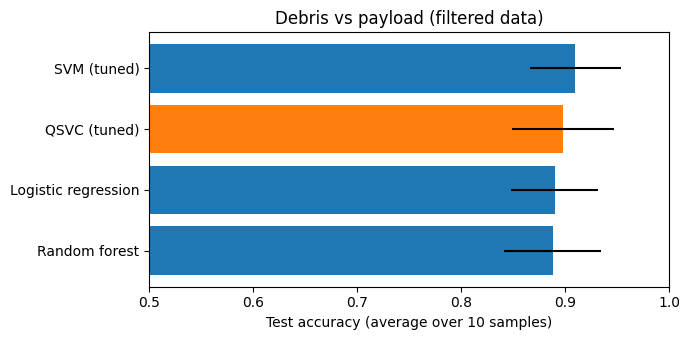

In [ ]:
# 1. Same quantum circuit as Part 1 (ZZ feature map, 4 qubits, reps=2)
fair_map = zz_feature_map(feature_dimension=N_QUBITS, reps=2)
fair_kernel = FidelityStatevectorKernel(feature_map=fair_map)

BANDWIDTHS = [0.1, 0.25, 0.5, 1.0]
CS = [0.1, 1, 10, 100]

# 2. Helper to compute the quantum kernel with a chosen bandwidth
def qkernel(A, B=None, lam=1.0, kernel=fair_kernel):
    if B is None:
        return kernel.evaluate(A * lam * np.pi)
    return kernel.evaluate(A * lam * np.pi, B * lam * np.pi)

# 3. Pick the best bandwidth and C using the validation set
def best_qsvc(X_train, y_train, X_val, y_val, kernel=fair_kernel):
    best = (-1, None, None)
    for lam in BANDWIDTHS:
        K_train = qkernel(X_train, lam=lam, kernel=kernel)
        K_val = qkernel(X_val, X_train, lam=lam, kernel=kernel)
        for C in CS:
            acc = SVC(kernel="precomputed", C=C).fit(K_train, y_train).score(K_val, y_val)
            if acc > best[0]:
                best = (acc, lam, C)
    return best

# 4. Classical models, each tuned with 5-fold cross-validation
def classical_models():
    return {
        "SVM (tuned)": GridSearchCV(SVC(), {"C": CS, "gamma": ["scale", 0.1, 1, 10]}, cv=5),
        "Random forest": GridSearchCV(RandomForestClassifier(random_state=0), {"max_depth": [3, 5, None]}, cv=5),
        "Logistic regression": GridSearchCV(LogisticRegression(max_iter=2000), {"C": CS}, cv=5),
    }

# 5. Run everything on 10 random samples and score each model once on the test set
results = []
start = time.time()
for seed in SEEDS:
    X_train, y_train, X_val, y_val, X_test, y_test, _ = make_split(seed)

    _, lam, C = best_qsvc(X_train, y_train, X_val, y_val)
    model = SVC(kernel="precomputed", C=C).fit(qkernel(X_train, lam=lam), y_train)
    acc = model.score(qkernel(X_test, X_train, lam=lam), y_test)
    results.append({"seed": seed, "model": "QSVC (tuned)", "accuracy": acc, "lambda": lam})

    for name, m in classical_models().items():
        acc = m.fit(X_train, y_train).score(X_test, y_test)
        results.append({"seed": seed, "model": name, "accuracy": acc})

results = pd.DataFrame(results)
summary = results.groupby("model")["accuracy"].agg(["mean", "std"]).round(3).sort_values("mean")
print(f"Finished in {time.time() - start:.0f} seconds\n")
print(summary)
print("\nBandwidth chosen in each run:", results["lambda"].dropna().value_counts().to_dict())

# 6. Plot average test accuracy with error bars
plt.figure(figsize=(7, 3.5))
plt.barh(summary.index, summary["mean"], xerr=summary["std"],
         color=["tab:orange" if "QSVC" in m else "tab:blue" for m in summary.index])
plt.xlim(0.5, 1)
plt.xlabel("Test accuracy (average over 10 samples)")
plt.title("Debris vs payload (filtered data)")
plt.tight_layout()
plt.show()

Why the bandwidth matters
In the comparison above, the tuning almost always picked λ = 0.1. Here we check what happens for different λ values. In Part 1 the data was scaled to [0, π], which is the same as λ = 1. The right plot shows the average similarity between different objects in the quantum kernel. When it gets close to 0, every object looks completely different from every other one, and the model can only memorize the training data.

       accuracy        avg_similarity       
           mean    std           mean    std
lambda                                      
0.05      0.873  0.042          0.672  0.001
0.10      0.870  0.042          0.355  0.005
0.25      0.785  0.062          0.102  0.002
0.50      0.702  0.043          0.083  0.002
1.00      0.648  0.064          0.076  0.002
2.00      0.543  0.058          0.071  0.002


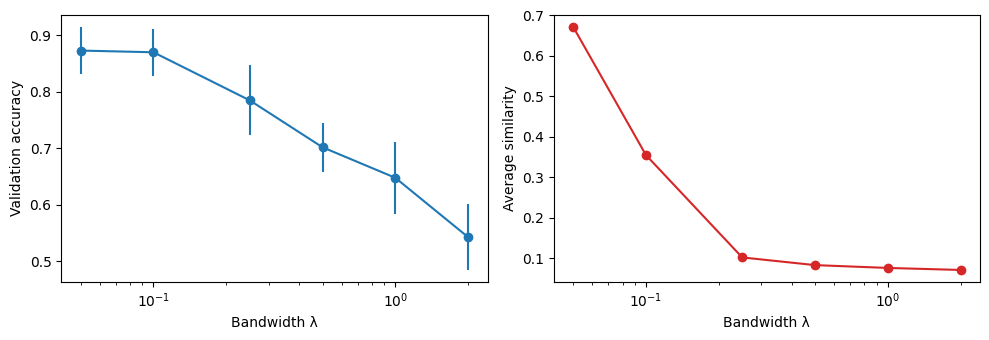

In [ ]:
# 1. Try different bandwidths with the same C, on all 10 random samples
sweep = []
for seed in SEEDS:
    X_train, y_train, X_val, y_val, *_ = make_split(seed)
    for lam in [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]:
        K_train = qkernel(X_train, lam=lam)
        K_val = qkernel(X_val, X_train, lam=lam)
        acc = SVC(kernel="precomputed", C=10).fit(K_train, y_train).score(K_val, y_val)

        # average similarity between different objects (ignore the diagonal, which is always 1)
        avg_sim = K_train[~np.eye(len(K_train), dtype=bool)].mean()
        sweep.append({"lambda": lam, "accuracy": acc, "avg_similarity": avg_sim})

sweep = pd.DataFrame(sweep).groupby("lambda").agg(["mean", "std"]).round(3)
print(sweep)

# 2. Plot accuracy and average similarity against the bandwidth
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].errorbar(sweep.index, sweep[("accuracy", "mean")], sweep[("accuracy", "std")], marker="o")
ax[0].set_xscale("log")
ax[0].set_xlabel("Bandwidth λ")
ax[0].set_ylabel("Validation accuracy")
ax[1].plot(sweep.index, sweep[("avg_similarity", "mean")], marker="o", color="tab:red")
ax[1].set_xscale("log")
ax[1].set_xlabel("Bandwidth λ")
ax[1].set_ylabel("Average similarity")
plt.tight_layout()
plt.show()

Testing the quantum kernel with noise
So far the quantum kernel has been calculated exactly. A real quantum computer has to estimate each similarity value by running the circuit many times (shots), and its gates and measurements also make small errors. We test the same kernel three ways:

1. Ideal: exact values, no noise
2. Shot noise: a perfect simulator, but each value is estimated from 2,000 shots
3. Device noise: a simulator that copies the errors of a real IBM processor (FakeTorino)

Since the number of circuits grows quickly with the data size, we use a smaller set of 40 training and 20 test objects. Each similarity is measured by running the circuit for one object, then the reverse circuit for the other object, and checking how often all qubits come back as 0.

Bandwidth: 0.1  C: 0.1
Ideal                        test accuracy = 0.800   (1s)
Shot noise (2000 shots)      test accuracy = 0.800   (38s)
Device noise (FakeTorino)    test accuracy = 0.800   (85s)


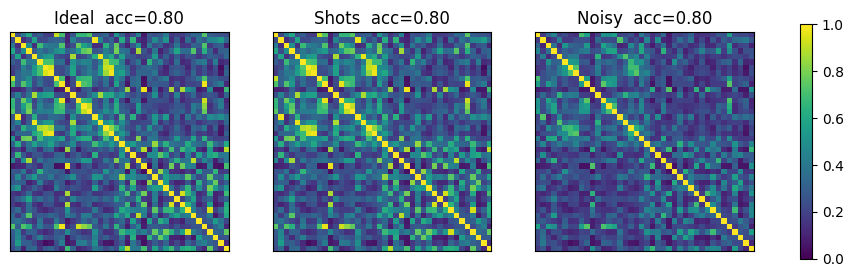

Average difference between noisy and ideal kernel: 0.0764


In [ ]:
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeTorino

# 1. Use the first random sample and pick lambda and C the same way as before
X_train, y_train, X_val, y_val, X_test, y_test, _ = make_split(0)
_, LAM, C_BEST = best_qsvc(X_train, y_train, X_val, y_val)
print("Bandwidth:", LAM, " C:", C_BEST)

# 2. Take a smaller balanced subset: 40 training objects and 20 test objects
rng = np.random.default_rng(0)
train_idx = np.concatenate([rng.choice(np.where(y_train == k)[0], 20, replace=False) for k in (0, 1)])
test_idx = np.concatenate([rng.choice(np.where(y_test == k)[0], 10, replace=False) for k in (0, 1)])
X_tr_small, y_tr_small = X_train[train_idx], y_train[train_idx]
X_te_small, y_te_small = X_test[test_idx], y_test[test_idx]

# 3. Build a kernel that is estimated from shots on a given simulator
def shot_kernel(backend, sampler):
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=1)
    fidelity = ComputeUncompute(sampler=sampler, pass_manager=pm)
    return FidelityQuantumKernel(feature_map=fair_map, fidelity=fidelity)

# 4. Train and test the QSVC with a given kernel
def run(kernel, name):
    start = time.time()
    K_tr = qkernel(X_tr_small, lam=LAM, kernel=kernel)
    K_te = qkernel(X_te_small, X_tr_small, lam=LAM, kernel=kernel)
    acc = SVC(kernel="precomputed", C=C_BEST).fit(K_tr, y_tr_small).score(K_te, y_te_small)
    print(f"{name:28s} test accuracy = {acc:.3f}   ({time.time() - start:.0f}s)")
    return K_tr, acc

# 5. Run the three versions
K_ideal, acc_ideal = run(fair_kernel, "Ideal")
K_shots, acc_shots = run(shot_kernel(AerSimulator(), AerSampler(default_shots=2000, seed=1)),
                         "Shot noise (2000 shots)")
K_noisy, acc_noisy = run(shot_kernel(AerSimulator.from_backend(FakeTorino()),
                                     AerSampler.from_backend(FakeTorino(), default_shots=2000, seed=1)),
                         "Device noise (FakeTorino)")

# 6. Show the three kernels side by side
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for axis, K, title in zip(ax, [K_ideal, K_shots, K_noisy],
                          [f"Ideal  acc={acc_ideal:.2f}", f"Shots  acc={acc_shots:.2f}", f"Noisy  acc={acc_noisy:.2f}"]):
    im = axis.imshow(K, vmin=0, vmax=1, cmap="viridis")
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print("Average difference between noisy and ideal kernel:", np.abs(K_noisy - K_ideal).mean().round(4))

Running on real IBM quantum hardware
We ran the same 40 training / 20 test kernel on ibm_kingston, a 156-qubit IBM Heron processor, using the free IBM Quantum Open Plan. Each circuit was run 500 times, with error suppression turned on (dynamical decoupling and gate twirling). The run took about 21 minutes including waiting in the queue, so we saved the result to a file (K_hw_train.npy) and load it here instead of running it again.

The hardware run gave a test accuracy of 0.80, the same as the ideal and noisy simulations. Below we compare the kernel measured on hardware with the ideal one.

Hardware kernel shape: (40, 40)
Correlation with ideal:       0.99
Average difference:           0.0809
Average similarity ideal/hw:  0.342 / 0.262


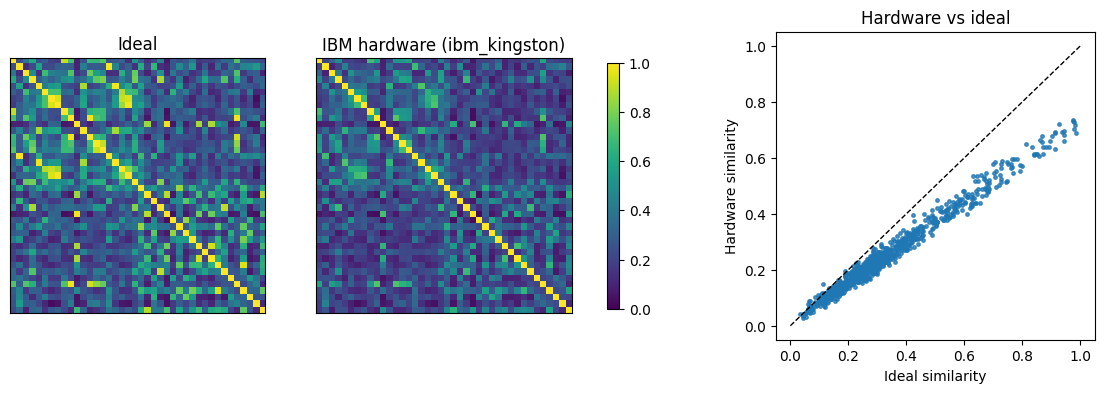

In [ ]:
# 1. Load the kernel measured on ibm_kingston (40 x 40 training objects, same subset as above)
K_hw = np.load("/content/drive/MyDrive/qhack/K_hw_train.npy")
print("Hardware kernel shape:", K_hw.shape)

# 2. Compare hardware values with the ideal values (ignore the diagonal, which is always 1)
off_diag = ~np.eye(len(K_hw), dtype=bool)
print("Correlation with ideal:      ", np.corrcoef(K_hw[off_diag], K_ideal[off_diag])[0, 1].round(3))
print("Average difference:          ", np.abs(K_hw - K_ideal)[off_diag].mean().round(4))
print("Average similarity ideal/hw: ", K_ideal[off_diag].mean().round(3), "/", K_hw[off_diag].mean().round(3))

# 3. Plot the ideal and hardware kernels, and each hardware value against its ideal value
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for axis, K, title in zip(ax[:2], [K_ideal, K_hw], ["Ideal", "IBM hardware (ibm_kingston)"]):
    im = axis.imshow(K, vmin=0, vmax=1, cmap="viridis")
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
fig.colorbar(im, ax=list(ax[:2]), shrink=0.8)

ax[2].scatter(K_ideal[off_diag], K_hw[off_diag], s=6, alpha=0.5)
ax[2].plot([0, 1], [0, 1], "k--", lw=1)   # points on this line would match perfectly
ax[2].set_xlabel("Ideal similarity")
ax[2].set_ylabel("Hardware similarity")
ax[2].set_title("Hardware vs ideal")
plt.show()

Which breakup event did a debris piece come from?
When a satellite explodes or is hit, it breaks into thousands of fragments. Knowing which event a fragment came from helps track debris clouds and understand collision risk. In the catalog, the first 8 characters of OBJECT_ID (the launch designator) tell us which launch each fragment belongs to, so we get labels for free.

We picked four of the biggest breakup events in low Earth orbit:
- 1999-025: Fengyun-1C, destroyed in China's 2007 anti-satellite test (1,904 fragments)
- 1993-036: Cosmos 2251, destroyed in the 2009 collision with Iridium 33 (569 fragments)
- 2022-151: Long March 6A rocket stage breakup in 2022 (612 fragments)
- 2024-140: Long March 6A rocket stage breakup in 2024 (571 fragments)

This is harder than it sounds, because Fengyun-1C and the 2022 Long March debris sit at almost the same tilt and height. We use 4 features (inclination, eccentricity, mean motion and RAAN, the direction the orbit plane faces), 60 fragments per event, and the same tuning as before, over 6 random samples. Random guessing would get 25%.

In [ ]:
# 1. The four breakup events (launch designator -> name)
FAMILIES = {
    "1999-025": "Fengyun-1C (2007 ASAT test)",
    "1993-036": "Cosmos 2251 (2009 collision)",
    "2022-151": "CZ-6A stage (2022 breakup)",
    "2024-140": "CZ-6A stage (2024 breakup)",
}
ATTR_FEATURES = ["INCLINATION", "ECCENTRICITY", "MEAN_MOTION", "RA_OF_ASC_NODE"]
classes = list(FAMILIES)

# 2. Keep debris from these four events and label each piece with its parent event
frag = leo[leo["OBJECT_TYPE"] == "DEBRIS"].copy()
frag["PARENT"] = frag["OBJECT_ID"].str[:8]
frag = frag[frag["PARENT"].isin(FAMILIES)]
print(frag["PARENT"].map(FAMILIES).value_counts())

attr_kernel = FidelityStatevectorKernel(feature_map=zz_feature_map(len(ATTR_FEATURES), reps=2))

# 3. Balanced sample of 60 fragments per event, split 60/20/20 and scaled like before
def attr_split(seed, n_per_class=60):
    sample = pd.concat([frag[frag.PARENT == p].sample(n_per_class, random_state=seed) for p in classes])
    X = sample[ATTR_FEATURES].values
    y = sample["PARENT"].map({p: i for i, p in enumerate(classes)}).values
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=seed, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed, stratify=y_temp)
    scaler = QuantileTransformer(n_quantiles=100).fit(X_train)
    return scaler.transform(X_train), y_train, scaler.transform(X_val), y_val, scaler.transform(X_test), y_test

# 4. Quantum vs classical on 6 random samples
attr_results = []
for seed in range(6):
    X_train, y_train, X_val, y_val, X_test, y_test = attr_split(seed)

    # pick bandwidth and C on the validation set
    best = (-1, None, None)
    for lam in [0.05, 0.1, 0.25]:
        K_train = attr_kernel.evaluate(X_train * lam * np.pi)
        K_val = attr_kernel.evaluate(X_val * lam * np.pi, X_train * lam * np.pi)
        for C in CS:
            acc = SVC(kernel="precomputed", C=C).fit(K_train, y_train).score(K_val, y_val)
            if acc > best[0]:
                best = (acc, lam, C)
    _, lam, C = best

    model = SVC(kernel="precomputed", C=C).fit(attr_kernel.evaluate(X_train * lam * np.pi), y_train)
    acc = model.score(attr_kernel.evaluate(X_test * lam * np.pi, X_train * lam * np.pi), y_test)
    attr_results.append({"model": "QSVC (tuned)", "accuracy": acc})

    for name, m in classical_models().items():
        attr_results.append({"model": name, "accuracy": m.fit(X_train, y_train).score(X_test, y_test)})

attr_summary = pd.DataFrame(attr_results).groupby("model")["accuracy"].agg(["mean", "std"]).round(3).sort_values("mean")
print("\nBreakup attribution test accuracy (random guessing = 0.25):")
print(attr_summary)

PARENT
Fengyun-1C (2007 ASAT test)     1904
CZ-6A stage (2022 breakup)       612
CZ-6A stage (2024 breakup)       571
Cosmos 2251 (2009 collision)     569
Name: count, dtype: int64

Breakup attribution test accuracy (random guessing = 0.25):
                      mean    std
model                            
Logistic regression  0.809  0.062
QSVC (tuned)         0.882  0.025
SVM (tuned)          0.885  0.029
Random forest        0.896  0.054


Part 2 summary
- On filtered data (low Earth orbit, no large constellations), the tuned QSVC reached 0.898 ± 0.049 test accuracy, close to the tuned classical SVM (0.910), logistic regression (0.890) and random forest (0.888). The quantum kernel is competitive, but it does not beat well-tuned classical models on this task.
- The bandwidth λ decides whether the quantum kernel works at all. With the Part 1 scaling (λ = 1), accuracy drops to 0.65 because almost every pair of objects looks completely different. With λ = 0.1, accuracy reaches 0.87 to 0.90.
- The kernel is robust to noise. Ideal, shot noise, simulated IBM device noise and the real ibm_kingston processor all gave 0.80 test accuracy on the same 40 / 20 subset.
- On real hardware, the measured kernel had a 0.99 correlation with the ideal one. Noise lowered all similarity values by about the same amount (0.34 to 0.26), but kept their order, which is what the SVM relies on.
- On a new and harder task, identifying which of four breakup events a debris fragment came from, the QSVC was right 88% of the time (random guessing: 25%). This is about the same as the tuned SVM (0.885) and random forest (0.896), better than logistic regression (0.809), and the QSVC was the most consistent across random samples (lowest std).
- Limitation: the noise and hardware tests used only 20 test objects, so they show that hardware matches simulation, not that it is better.